# Latihan Praktikum Bab 5: Pruning pada Decision Tree
Dataset: Telco Customer Churn. Jalankan dari atas ke bawah (**Shift+Enter** pada tiap sel), atau **Runtime → Run all**.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score

import os
# Baca dari folder data/ jika ada (repositori lokal); jika tidak (misalnya di Colab), ambil dari internet
lokal = "../data/Telco-Customer-Churn.csv"
url = lokal if os.path.exists(lokal) else "https://raw.githubusercontent.com/IBM/telco-customer-churn-on-icp4d/master/data/Telco-Customer-Churn.csv"
df = pd.read_csv(url)
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")
df = df.dropna().drop(columns="customerID")
df["Churn"] = (df["Churn"] == "Yes").astype(int)
df = pd.get_dummies(df, drop_first=True)

X = df.drop(columns="Churn")
y = df["Churn"]
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42
)
print("Data latih:", X_train.shape, "| Data uji:", X_test.shape)

Data latih: (5625, 30) | Data uji: (1407, 30)


---
# Praktikum 1: Eksperimen Parameter Pre-Pruning (Praktikum 5.7)
Pre-pruning membatasi pertumbuhan pohon sejak awal lewat `max_depth` dan `min_samples_leaf`.

In [2]:
# Praktikum 5.7 (kode di buku)
for depth in [2, 4, 6, None]:
    for min_leaf in [1, 5, 10]:
        model = DecisionTreeClassifier(max_depth=depth,
                                       min_samples_leaf=min_leaf, random_state=42)
        model.fit(X_train, y_train)
        acc = accuracy_score(y_test, model.predict(X_test))
        print(f"max_depth={depth}, min_samples_leaf={min_leaf}: akurasi test={acc:.3f}")

max_depth=2, min_samples_leaf=1: akurasi test=0.785
max_depth=2, min_samples_leaf=5: akurasi test=0.785
max_depth=2, min_samples_leaf=10: akurasi test=0.785
max_depth=4, min_samples_leaf=1: akurasi test=0.783
max_depth=4, min_samples_leaf=5: akurasi test=0.783
max_depth=4, min_samples_leaf=10: akurasi test=0.783
max_depth=6, min_samples_leaf=1: akurasi test=0.785
max_depth=6, min_samples_leaf=5: akurasi test=0.785
max_depth=6, min_samples_leaf=10: akurasi test=0.784
max_depth=None, min_samples_leaf=1: akurasi test=0.719
max_depth=None, min_samples_leaf=5: akurasi test=0.746
max_depth=None, min_samples_leaf=10: akurasi test=0.762


In [3]:
# Tambahan: tabel lengkap dengan akurasi train, gap, dan jumlah leaf
baris = []
for depth in [2, 4, 6, None]:
    for min_leaf in [1, 5, 10]:
        m = DecisionTreeClassifier(max_depth=depth, min_samples_leaf=min_leaf,
                                   random_state=42).fit(X_train, y_train)
        tr = m.score(X_train, y_train)
        te = m.score(X_test, y_test)
        baris.append({"max_depth": str(depth), "min_samples_leaf": min_leaf,
                      "Akurasi train": round(tr, 3), "Akurasi test": round(te, 3),
                      "Gap": round(tr - te, 3), "Jumlah leaf": m.get_n_leaves()})
hasil5_7 = pd.DataFrame(baris)
hasil5_7

,max_depth,min_samples_leaf,Akurasi train,Akurasi test,Gap,Jumlah leaf
0,2,1,0.791,0.785,0.007,4
1,2,5,0.791,0.785,0.007,4
2,2,10,0.791,0.785,0.007,4
3,4,1,0.796,0.783,0.013,16
4,4,5,0.796,0.783,0.013,16
5,4,10,0.796,0.783,0.013,16
6,6,1,0.813,0.785,0.028,58
7,6,5,0.811,0.785,0.026,55
8,6,10,0.810,0.784,0.027,58
9,None,1,0.999,0.719,0.280,1112


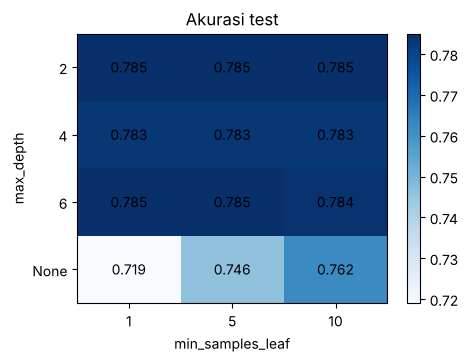

In [4]:
# Heatmap akurasi test
pivot = hasil5_7.pivot(
    index="max_depth", columns="min_samples_leaf", values="Akurasi test"
).loc[["2", "4", "6", "None"]]
plt.figure(figsize=(5, 3.5))
plt.imshow(pivot.values, cmap="Blues", aspect="auto")
plt.xticks(range(3), pivot.columns); plt.yticks(range(4), pivot.index)
for i in range(4):
    for j in range(3):
        plt.text(j, i, f"{pivot.values[i, j]:.3f}", ha="center", va="center")
plt.xlabel("min_samples_leaf"); plt.ylabel("max_depth")
plt.title("Akurasi test"); plt.colorbar(); plt.show()

**Kesimpulan Praktikum 1 (isi/sesuaikan dengan output Anda):** Pohon tanpa batas (`max_depth=None`, `min_samples_leaf=1`) punya akurasi train 0,999 tetapi akurasi test hanya 0,719, gap 0,28, dan 1.112 leaf: ini overfitting. Pohon dengan `max_depth` 2, 4, atau 6 punya akurasi test hampir sama (0,783 sampai 0,785) dengan gap kecil, jadi pembatasan kedalaman saja sudah cukup efektif. Pada `max_depth` kecil, `min_samples_leaf` tidak berpengaruh karena leaf-nya memang sudah besar. Pengaruhnya baru terlihat pada pohon tanpa batas: menaikkan `min_samples_leaf` dari 1 ke 5 lalu 10 menaikkan akurasi test dari 0,719 ke 0,746 lalu 0,762 dan menurunkan jumlah leaf. Pohon yang paling sederhana (`max_depth=2`, hanya 4 leaf) sudah sebaik yang lain, yang menunjukkan bahwa pola pada data ini sederhana.

---
# Praktikum 2: Cost Complexity Pruning Path (Praktikum 5.8)
Post-pruning: pohon penuh ditumbuhkan dulu, lalu dipangkas dengan `ccp_alpha`. Semakin besar alpha, semakin kecil pohonnya.

Jumlah kandidat alpha: 437


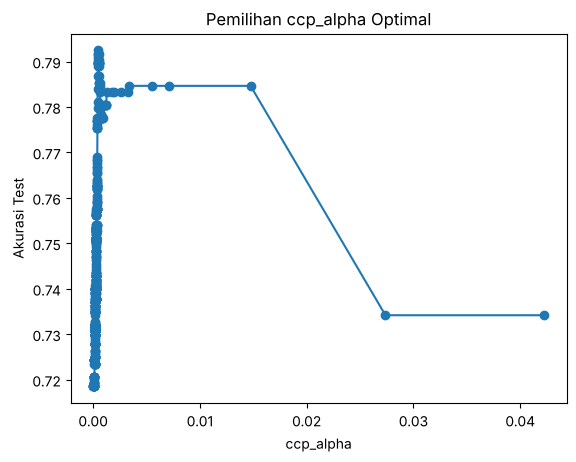

In [5]:
# Praktikum 5.8 (kode di buku)
tree_full = DecisionTreeClassifier(random_state=42).fit(X_train, y_train)
path = tree_full.cost_complexity_pruning_path(X_train, y_train)
print("Jumlah kandidat alpha:", len(path.ccp_alphas))

akurasi_test = []
for alpha in path.ccp_alphas:
    m = DecisionTreeClassifier(ccp_alpha=alpha,
                               random_state=42).fit(X_train, y_train)
    akurasi_test.append(accuracy_score(y_test, m.predict(X_test)))

plt.plot(path.ccp_alphas, akurasi_test, marker='o')
plt.xlabel("ccp_alpha"); plt.ylabel("Akurasi Test")
plt.title("Pemilihan ccp_alpha Optimal")
plt.show()

In [6]:
# Tentukan ccp_alpha dengan akurasi test tertinggi, lalu bandingkan jumlah leaf node-nya
idx = int(np.argmax(akurasi_test))
alpha_terbaik = path.ccp_alphas[idx]
pohon_pruned = DecisionTreeClassifier(ccp_alpha=alpha_terbaik,
                                      random_state=42).fit(X_train, y_train)

print(f"ccp_alpha terbaik       : {alpha_terbaik:.6f}")
print(f"Akurasi test tertinggi  : {akurasi_test[idx]:.4f}")
print()
print(f"{'':22}{'Pohon penuh':>14}{'Pohon pruned':>14}")
print(f"{'Jumlah leaf node':22}{tree_full.get_n_leaves():>14}{pohon_pruned.get_n_leaves():>14}")
print(f"{'Kedalaman':22}{tree_full.get_depth():>14}{pohon_pruned.get_depth():>14}")
print(f"{'Akurasi train':22}{tree_full.score(X_train, y_train):>14.3f}{pohon_pruned.score(X_train, y_train):>14.3f}")
print(f"{'Akurasi test':22}{tree_full.score(X_test, y_test):>14.3f}{pohon_pruned.score(X_test, y_test):>14.3f}")

ccp_alpha terbaik       : 0.000456
Akurasi test tertinggi  : 0.7925

                         Pohon penuh  Pohon pruned
Jumlah leaf node                1112            79
Kedalaman                         23            13
Akurasi train                  0.999         0.835
Akurasi test                   0.719         0.792


### Tambahan: memilih alpha dengan cross-validation
Memilih alpha dari akurasi **test** berarti data uji ikut dipakai untuk memilih model, sehingga akurasinya cenderung terlalu optimis. Buku sendiri (bagian 5.11.1) menyarankan memakai cross-validation. Berikut cara yang lebih benar: alpha dipilih dari data latih, data uji hanya dipakai sekali di akhir.

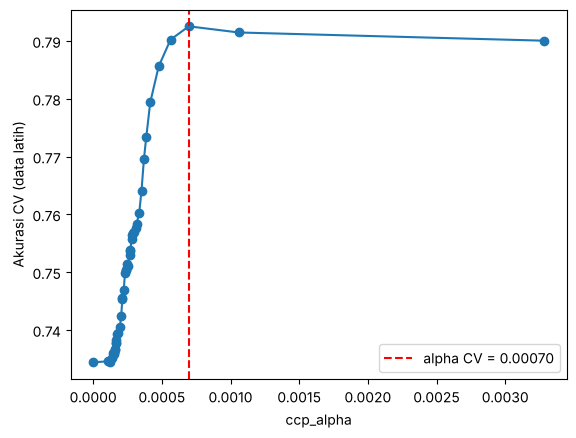

alpha terbaik (CV)  : 0.000696
Akurasi CV          : 0.7925
Jumlah leaf         : 31
Akurasi test (sekali): 0.7804


In [7]:
# Pilih alpha lewat 5-fold CV pada data latih (kandidat dikurangi supaya cepat)
kandidat = path.ccp_alphas[::max(1, len(path.ccp_alphas) // 40)]
skor_cv = [cross_val_score(DecisionTreeClassifier(ccp_alpha=a, random_state=42),
                           X_train, y_train, cv=5).mean() for a in kandidat]
alpha_cv = kandidat[int(np.argmax(skor_cv))]
pohon_cv = DecisionTreeClassifier(ccp_alpha=alpha_cv, random_state=42).fit(X_train, y_train)

plt.plot(kandidat, skor_cv, marker="o")
plt.axvline(alpha_cv, color="red", linestyle="--", label=f"alpha CV = {alpha_cv:.5f}")
plt.xlabel("ccp_alpha"); plt.ylabel("Akurasi CV (data latih)")
plt.legend(); plt.show()

print(f"alpha terbaik (CV)  : {alpha_cv:.6f}")
print(f"Akurasi CV          : {max(skor_cv):.4f}")
print(f"Jumlah leaf         : {pohon_cv.get_n_leaves()}")
print(f"Akurasi test (sekali): {pohon_cv.score(X_test, y_test):.4f}")

**Kesimpulan Praktikum 2 (isi/sesuaikan dengan output Anda):** Pohon penuh punya 1.112 leaf dan akurasi test 0,719 (overfitting). Dengan `ccp_alpha` terbaik (sekitar 0,000456), pohon menyusut menjadi 79 leaf dan akurasi test naik menjadi 0,792, sedangkan akurasi train turun dari 0,999 ke 0,835. Kurva akurasi vs alpha naik lalu turun: alpha terlalu kecil masih overfitting, alpha terlalu besar membuat pohon terlalu sederhana. Alpha yang dipilih lewat cross-validation (sekitar 0,0007, 31 leaf) memberi akurasi test 0,780, sedikit lebih rendah dari 0,792. Selisih itu menunjukkan bahwa memilih alpha dari data uji membuat akurasi tampak lebih bagus dari yang sebenarnya, jadi angka dari cross-validation lebih jujur.